In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
#import xgboost

print("Customer Churn Project Started!")
print("-------------------------------")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
#print("XGBoost:", xgboost.__version__)

Customer Churn Project Started!
-------------------------------
Pandas: 3.1.1
NumPy: 2.5.4
Scikit-learn: 1.9.1


In [3]:
import xgboost

print(xgboost.__version__)

3.4.1


In [4]:
import xgboost

print("XGBoost version:", xgboost.__version__)
print("XGBoost imported successfully!")

XGBoost version: 3.4.1
XGBoost imported successfully!


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")

In [7]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 7043
Number of columns: 21


In [9]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [11]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [13]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

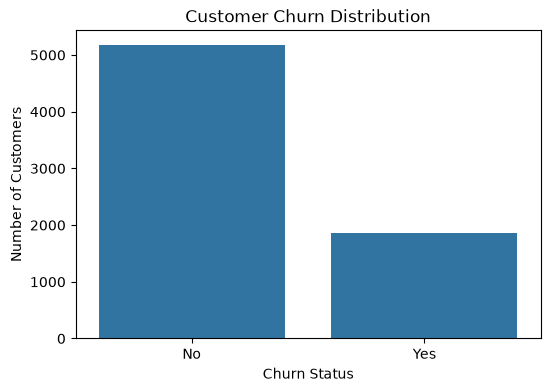

In [14]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

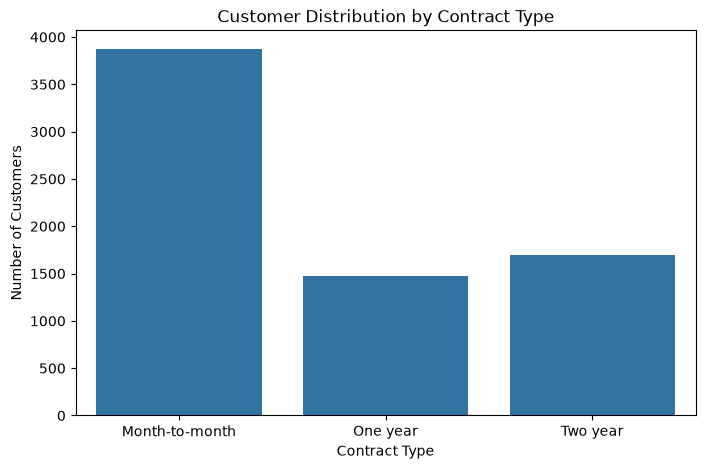

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract")

plt.title("Customer Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

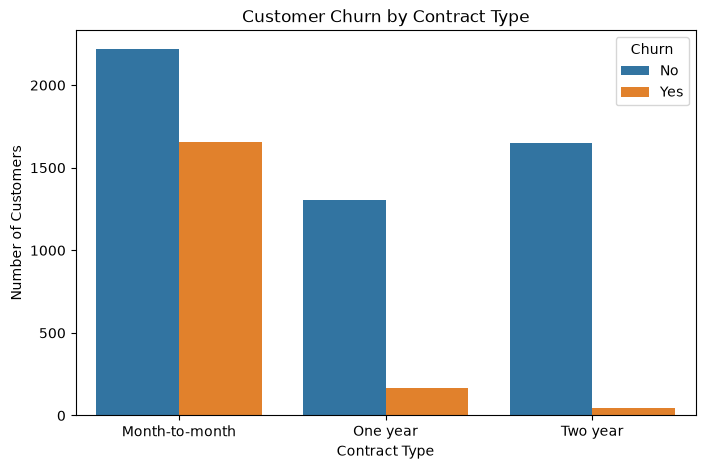

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()


In [17]:
df["tenure"].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

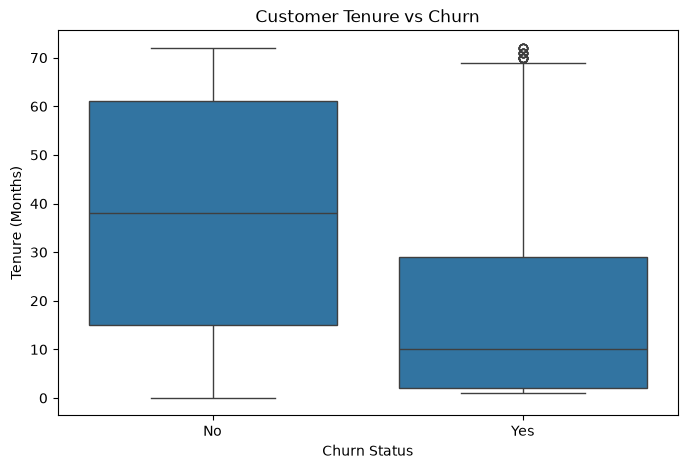

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.show()

## Finding: Customer Tenure vs Churn

The boxplot shows that customers who churn generally have shorter tenure than customers who stay with the company.

- Customers who stayed (`No`) have a median tenure of approximately **38 months**.
- Customers who churned (`Yes`) have a median tenure of approximately **10 months**.
- Customers who stayed generally have longer relationships with the company.
- Customers who churned tend to leave within a shorter period.

### Conclusion

Customer tenure appears to be an important feature associated with customer churn. Newer customers may be more likely to leave, so the company should focus on improving customer satisfaction and retention during the early months of the customer relationship.

In [19]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

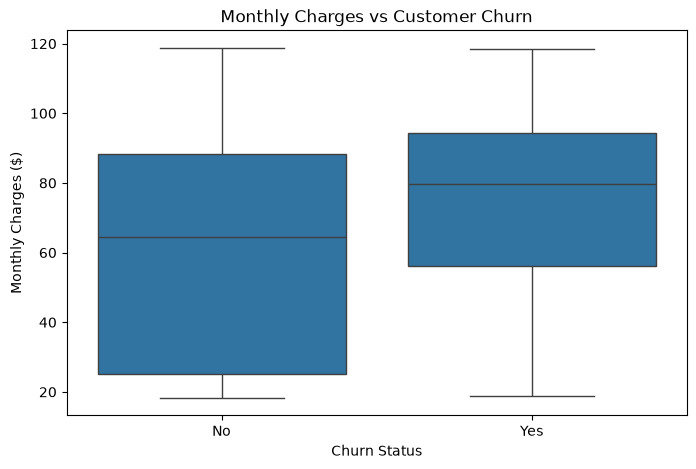

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges ($)")

plt.show()

## Finding: Monthly Charges vs Customer Churn

The analysis shows that customers who churn generally pay higher monthly charges than customers who stay.

- Customers who stayed (`No`) have an average monthly charge of approximately **$61.27**.
- Customers who churned (`Yes`) have an average monthly charge of approximately **$74.44**.
- Customers who churned pay approximately **$13.18 more per month** on average.
- The boxplot also shows a higher median monthly charge among customers who churned.

### Conclusion

Monthly charges appear to be associated with customer churn. Customers paying higher monthly bills may be more likely to leave the company. The company should investigate whether pricing, service costs, or service packages contribute to customer dissatisfaction.

In [21]:
df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

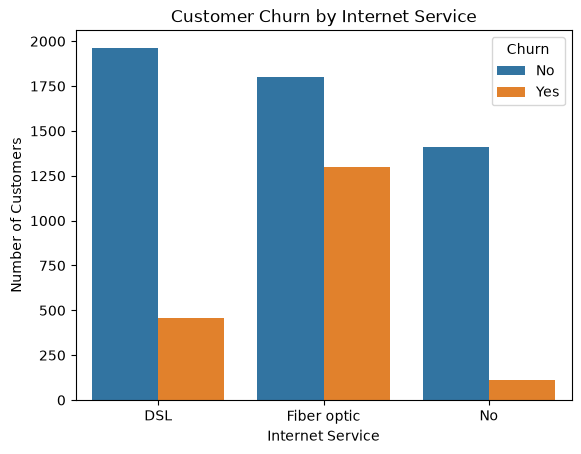

In [22]:
sns.countplot(data=df, x="InternetService", hue="Churn")

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [23]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


## Finding: Internet Service vs Customer Churn

The cross-tabulation analysis shows that customer churn rates differ across internet service categories.

- **Fiber optic:** 41.89% of customers churned.
- **DSL:** 18.96% of customers churned.
- **No internet service:** 7.40% of customers churned.

### Conclusion

Fiber optic customers have the highest churn rate, while customers without internet service have the lowest churn rate.

Internet service type appears to be an important feature associated with customer churn. The company should investigate pricing, service quality, and customer support, especially for Fiber optic customers.

These results show an association and do not establish that internet service type directly causes churn.

In [24]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


## Finding: Contract Type vs Customer Churn

The cross-tabulation analysis shows a significant difference in churn rates across contract types.

- **Month-to-month:** 42.71% of customers churned.
- **One year:** 11.27% of customers churned.
- **Two year:** 2.83% of customers churned.

### Conclusion

Month-to-month customers have the highest churn rate, while two-year contract customers have the lowest churn rate.

Contract type appears to be an important feature associated with customer churn. The company should focus on retaining month-to-month customers by providing attractive offers, loyalty rewards, and better customer support.

These findings show an association and do not establish that contract duration directly causes customer churn.

In [25]:
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [26]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


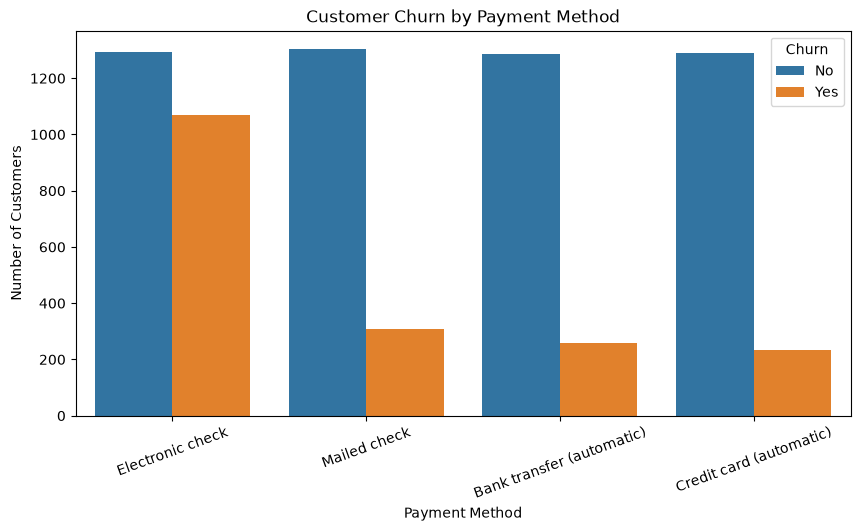

In [27]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="PaymentMethod", hue="Churn")

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.show()

### Finding: Payment Method vs Customer Churn

- Customers using electronic checks have the highest churn rate (45.29%).
- Customers using automatic credit card payments have the lowest churn rate (15.24%).
- Customers using automatic bank transfers also have a relatively low churn rate (16.71%).
- Automatic payment methods are associated with lower customer churn in this dataset.

**Business insight:** The company could investigate why electronic-check users leave more frequently and explore whether encouraging automatic payment options improves customer retention.

*Note: These results show an association, not necessarily a cause-and-effect relationship.*

In [28]:
paperless_churn = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

paperless_churn

Churn,No,Yes
PaperlessBilling,,
No,83.669916,16.330084
Yes,66.434908,33.565092


### Finding: Paperless Billing vs Customer Churn

- Customers using paperless billing have a churn rate of 33.57%.
- Customers not using paperless billing have a lower churn rate of 16.33%.
- Customers with paperless billing are more likely to churn in this dataset.

**Business insight:** The company could investigate whether paperless-billing customers have different service preferences, contract types, or customer experiences that contribute to higher churn.

*Note: This is an association, not proof of causation.*

In [29]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

senior_churn

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


### Finding: Senior Citizens vs Customer Churn

- Non-senior citizens have a churn rate of 23.61%.
- Senior citizens have a higher churn rate of 41.68%.
- Senior citizens are more likely to leave the company compared with non-senior citizens.

**Business insight:** The company could investigate the needs and experiences of senior customers and consider targeted customer retention strategies.

*Note: This relationship does not necessarily mean that being a senior citizen causes customer churn.*

In [30]:
partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

partner_churn

Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


### Finding: Partner Status vs Customer Churn

- Customers without a partner have a churn rate of 32.96%.
- Customers with a partner have a lower churn rate of 19.66%.
- Customers without a partner are more likely to leave the company.

**Business insight:** The company could investigate whether customers without partners have different service needs or engagement patterns and develop appropriate retention strategies.

*Note: This is an association, not proof of causation.*

In [31]:
dependents_churn = pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

dependents_churn

Churn,No,Yes
Dependents,,
No,68.720860,31.279140
Yes,84.549763,15.450237


### Finding: Dependents vs Customer Churn

- Customers without dependents have a churn rate of 31.28%.
- Customers with dependents have a lower churn rate of 15.45%.
- Customers without dependents are more likely to leave the company.

**Business insight:** The company could investigate the needs and service usage patterns of customers without dependents to identify opportunities for improving retention.

*Note: This is an association, not proof of causation.*

In [32]:
phone_churn = pd.crosstab(
    df["PhoneService"],
    df["Churn"],
    normalize="index"
) * 100

phone_churn

Churn,No,Yes
PhoneService,,
No,75.073314,24.926686
Yes,73.290363,26.709637


### Finding: Phone Service vs Customer Churn

- Customers without phone service have a churn rate of 24.93%.
- Customers with phone service have a churn rate of 26.71%.
- The difference between the two groups is relatively small (1.78 percentage points).

**Business insight:** Phone service availability alone does not appear to have a strong relationship with customer churn in this dataset.

*Note: This is a descriptive comparison, not proof that phone service has no predictive value.*

In [33]:
multiplelines_churn = pd.crosstab(
    df["MultipleLines"],
    df["Churn"],
    normalize="index"
) * 100

multiplelines_churn

Churn,No,Yes
MultipleLines,,
No,74.955752,25.044248
No phone service,75.073314,24.926686
Yes,71.390104,28.609896


### Finding: Multiple Lines vs Customer Churn

- Customers without multiple lines have a churn rate of 25.04%.
- Customers with multiple lines have a churn rate of 28.61%.
- Customers without phone service have a churn rate of 24.93%.
- Customers with multiple lines show a slightly higher churn rate than the other groups.

**Business insight:** Multiple phone lines alone do not appear to be a particularly strong indicator of churn in this dataset.

*Note: These results show associations, not causation.*

In [34]:
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

security_churn

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


### Finding: Online Security vs Customer Churn

- Customers without online security have a churn rate of 41.77%.
- Customers with online security have a much lower churn rate of 14.61%.
- Customers without internet service have a churn rate of 7.40%.
- OnlineSecurity appears to have a strong relationship with customer churn.

**Business insight:** The company could investigate whether customers without online security are less satisfied with their internet service or perceive less value in their subscriptions.

*Note: This is an association, not proof of causation.*

In [35]:
backup_churn = pd.crosstab(
    df["OnlineBackup"],
    df["Churn"],
    normalize="index"
) * 100

backup_churn

Churn,No,Yes
OnlineBackup,,
No,60.071244,39.928756
No internet service,92.595020,7.404980
Yes,78.468506,21.531494


### Finding: Online Backup vs Customer Churn

- Customers without online backup have a churn rate of 39.93%.
- Customers with online backup have a lower churn rate of 21.53%.
- Customers without internet service have a churn rate of 7.40%.
- Customers without OnlineBackup are more likely to churn.

**Business insight:** The company could investigate whether customers without online backup perceive less value in their internet subscriptions and explore opportunities to improve service engagement.

*Note: This is an association, not proof of causation.*

In [36]:
deviceprotection_churn = pd.crosstab(
    df["DeviceProtection"],
    df["Churn"],
    normalize="index"
) * 100

deviceprotection_churn

Churn,No,Yes
DeviceProtection,,
No,60.872375,39.127625
No internet service,92.595020,7.404980
Yes,77.497936,22.502064


### Finding: Device Protection vs Customer Churn

- Customers without device protection have a churn rate of 39.13%.
- Customers with device protection have a lower churn rate of 22.50%.
- Customers without internet service have a churn rate of 7.40%.
- Customers without DeviceProtection are more likely to churn.

**Business insight:** The company could investigate whether customers without device protection perceive less value in their subscriptions and explore ways to improve customer engagement.

*Note: This is an association, not proof of causation.*

In [37]:
techsupport_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

techsupport_churn

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


### Finding: Tech Support vs Customer Churn

- Customers without technical support have a churn rate of 41.64%.
- Customers with technical support have a much lower churn rate of 15.17%.
- Customers without internet service have a churn rate of 7.40%.
- Customers without TechSupport are considerably more likely to churn.

**Business insight:** The company could investigate whether customers without technical support experience more service difficulties and explore ways to improve their support experience.

*Note: This is an association, not proof of causation.*

In [38]:
streamingtv_churn = pd.crosstab(
    df["StreamingTV"],
    df["Churn"],
    normalize="index"
) * 100

streamingtv_churn

Churn,No,Yes
StreamingTV,,
No,66.476868,33.523132
No internet service,92.595020,7.404980
Yes,69.929812,30.070188


### Finding: Streaming TV vs Customer Churn

- Customers without StreamingTV have a churn rate of 33.52%.
- Customers with StreamingTV have a churn rate of 30.07%.
- The difference between the two groups is relatively small (3.45 percentage points).
- StreamingTV does not show a particularly strong relationship with churn in this comparison.

**Business insight:** The company could investigate whether its TV streaming packages meet customer expectations, but this feature alone does not indicate a major difference in customer retention.

*Note: This is an association, not proof of causation.*

In [39]:
streamingmovies_churn = pd.crosstab(
    df["StreamingMovies"],
    df["Churn"],
    normalize="index"
) * 100

streamingmovies_churn

Churn,No,Yes
StreamingMovies,,
No,66.319569,33.680431
No internet service,92.595020,7.404980
Yes,70.058565,29.941435


++### Finding: Streaming Movies vs Customer Churn

- Customers without StreamingMovies have a churn rate of 33.68%.
- Customers with StreamingMovies have a lower churn rate of 29.94%.
- The difference between the two groups is relatively small (3.74 percentage points).
- StreamingMovies shows a relatively weak relationship with churn compared with features such as Contract, OnlineSecurity, and TechSupport.

**Business insight:** The company could investigate whether its streaming packages meet customer expectations and whether customers who subscribe to multiple entertainment services show different retention patterns.

*Note: This is an association, not proof of causation.*

In [40]:
gender_churn = pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

gender_churn

Churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


### Finding: Gender vs Customer Churn

- Female customers have a churn rate of 26.92%.
- Male customers have a churn rate of 26.16%.
- The difference between the two groups is only 0.76 percentage points.
- Gender does not show a meaningful difference in churn rates in this dataset.

**Business insight:** Gender alone does not appear to be a strong indicator of customer churn.

*Note: This is a descriptive comparison, not proof that gender has no predictive value.*

In [41]:
df["TotalCharges"].dtype

<StringDtype(na_value=nan)>

In [42]:
df["TotalCharges"].head(10)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str

In [43]:
df["TotalCharges"].isna().sum()


np.int64(0)

In [44]:
(df["TotalCharges"].str.strip() == "").sum()

np.int64(11)

In [45]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [46]:
df["TotalCharges"].dtype

dtype('float64')

In [47]:
df["TotalCharges"].isna().sum()

np.int64(11)

In [48]:
df["TotalCharges"].describe()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64

In [49]:
df.groupby("Churn")["TotalCharges"].mean()

Churn
No     2555.344141
Yes    1531.796094
Name: TotalCharges, dtype: float64

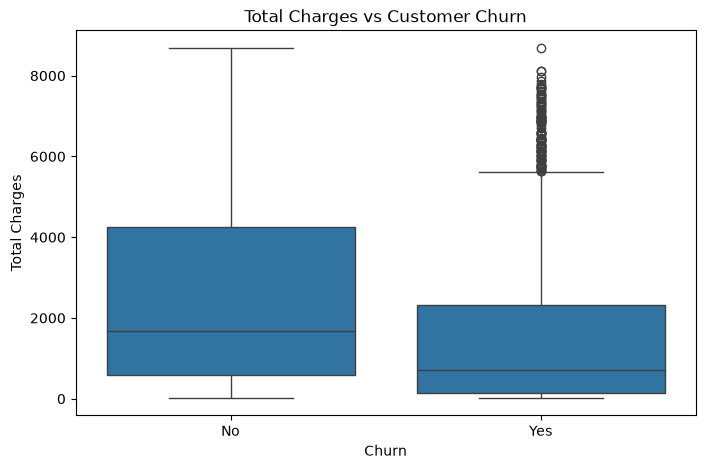

In [50]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges"
)

plt.title("Total Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Total Charges")

plt.show()

### Finding: Total Charges vs Customer Churn

- Customers who stayed have an average TotalCharges of approximately $2,555.34.
- Customers who churned have an average TotalCharges of approximately $1,531.80.
- Customers who stayed generally have higher cumulative charges than customers who churned.
- The boxplot also shows a lower median TotalCharges among churned customers.

**Business insight:** Customers who leave may have shorter relationships with the company, resulting in lower accumulated charges. The company could investigate customer behavior during the early stages of their subscription.

*Note: TotalCharges is closely related to tenure, so these findings should not be interpreted as evidence that lower spending causes churn.*

In [51]:
df.duplicated().sum()

np.int64(0)

In [52]:
df[df["TotalCharges"].isna()][
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [53]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [54]:
df["TotalCharges"].isna().sum()

np.int64(0)

In [55]:
df.isnull().sum().sum()

np.int64(0)

In [56]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [57]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [58]:
df.shape

(7043, 21)

In [59]:
df.to_csv(
    "../data/processed/cleaned_customer_churn.csv",
    index=False
)
